In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## accuracy-vs-parameters

**Figure 1: ImageNet top-1 accuracy versus number of parameters for EfficientNets and other ConvNets.** The solid line connects EfficientNet-B0 to B7 (B1 and B2 unlabelled), and the dashed and dotted grey lines connect the NAS and hand-designed baselines. EfficientNet-B7 reaches 84.4% with 66M parameters, above the best baseline, AmoebaNet-C (83.5%), which uses 2.3× more parameters.

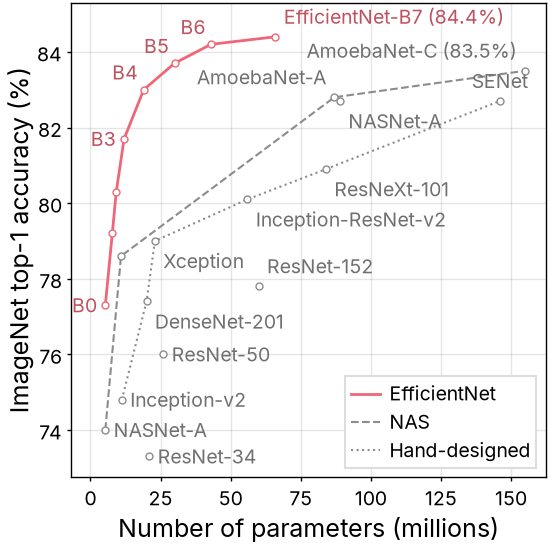

In [2]:
with open("../data/accuracy-vs-parameters.json") as f:
    models = {m["model"]: m for m in json.load(f)}

fig, ax = plt.subplots(figsize=(2.75, 2.75))

families = [
    ("EfficientNet", "EfficientNet", colors["ours"], "-"),
    ("NAS (dashed blue front)", "NAS", colors["neutral"], "--"),
    ("hand-designed (dotted gray front)", "Hand-designed", colors["neutral"], ":"),
]
for family, name, color, linestyle in families:
    points = sorted((m["params_millions"], m["top1_accuracy"]) for m in models.values() if m["family"] == family)
    x, y = zip(*points)
    width = plt.rcParams["lines.linewidth"] if linestyle == "-" else paper.dashed_width
    ax.plot(x, y, color=color, linestyle=linestyle, linewidth=width, zorder=1, label=name)
    ax.plot(x, y, "o", color=color, linestyle="none")
others = [m for m in models.values() if m["family"] == "other (no line)"]
ax.plot([m["params_millions"] for m in others], [m["top1_accuracy"] for m in others], "o",
        color=colors["neutral"], linestyle="none")

# label, offset in points, alignment; placed by hand so no label sits on a line or another label
labels = {
    "EfficientNet-B0": ("B0", -3, 0, "right", "center"),
    "EfficientNet-B3": ("B3", -3, 0, "right", "center"),
    "EfficientNet-B4": ("B4", -2, 2, "right", "bottom"),
    "EfficientNet-B5": ("B5", -2, 2, "right", "bottom"),
    "EfficientNet-B6": ("B6", -2, 2, "right", "bottom"),
    "EfficientNet-B7": ("EfficientNet-B7 (84.4%)", 3, 3, "left", "bottom"),
    "AmoebaNet-C": ("AmoebaNet-C (83.5%)", -3, 3, "right", "bottom"),
    "AmoebaNet-A": ("AmoebaNet-A", -3, 3, "right", "bottom"),
    "NASNet-A (large)": ("NASNet-A", 3, -3, "left", "top"),
    "SENet": ("SENet", 0, 3, "center", "bottom"),
    "ResNeXt-101": ("ResNeXt-101", 3, -3, "left", "top"),
    "Inception-ResNet-v2": ("Inception-ResNet-v2", 3, -3, "left", "top"),
    "Xception": ("Xception", 3, -3, "left", "top"),
    "DenseNet-201": ("DenseNet-201", 3, -3, "left", "top"),
    "ResNet-152": ("ResNet-152", 3, 3, "left", "bottom"),
    "ResNet-50": ("ResNet-50", 3, 0, "left", "center"),
    "Inception-v2": ("Inception-v2", 3, 0, "left", "center"),
    "NASNet-A (mobile)": ("NASNet-A", 3, 0, "left", "center"),
    "ResNet-34": ("ResNet-34", 3, 0, "left", "center"),
}
for model, (label, dx, dy, ha, va) in labels.items():
    m = models[model]
    color = colors["ours"] if m["family"] == "EfficientNet" else colors["neutral"]
    ax.annotate(label, (m["params_millions"], m["top1_accuracy"]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, fontsize=7, color=darken(color))

ax.set_xlabel("Number of parameters (millions)")
ax.set_ylabel("ImageNet top-1 accuracy (%)")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/accuracy-vs-parameters.pdf")
fig.savefig("../outputs/accuracy-vs-parameters.png")
plt.show()